# Análisis Exploratorio: Tipo de Cambio USD/MXN, Inflación (INPC) y Variables Macroeconómicas

Este notebook permite explorar y contrastar la relación entre el **Tipo de Cambio FIX (USD/MXN)**, la **Inflación Anual (INPC)**, las finanzas públicas (ingresos y gastos reales) y los sectores del IGAE, utilizando la Capa Gold generada en `data/processed/proyecto_integrado_mensual.parquet`.

El análisis se realiza a través de **rendimientos y variaciones interanuales (12 meses)** para garantizar comparabilidad entre variables.

In [1]:
import os
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Ajuste al directorio raíz si se ejecuta dentro de notebooks/
if Path.cwd().name == "notebooks" and (Path.cwd().parent / "pipeline.py").exists():
    os.chdir("..")

DATA_PATH = Path("data/processed/proyecto_integrado_mensual.parquet")
print("Ruta del dataset:", DATA_PATH)

df = pd.read_parquet(DATA_PATH)
df["PERIODO"] = pd.to_datetime(df["PERIODO"])
df = df.sort_values("PERIODO").reset_index(drop=True)

print(f"Dimensiones: {df.shape[0]} filas x {df.shape[1]} columnas")
display(df.head(5))

Ruta del dataset: data\processed\proyecto_integrado_mensual.parquet
Dimensiones: 283 filas x 12 columnas


,PERIODO,INGRESOS_REALES,GASTOS_REALES,Total,INPC,Actividades primarias,Actividades secundarias,Actividades terciarias,TC_CIERRE,SP500_CIERRE,SP500_PROMEDIO,VIX_CIERRE
0,2003-01-01,3.133723e+08,2.839016e+08,72.570800,53.525441,78.772727,80.862039,67.515524,10.9069,855.700012,895.836190,31.170000
1,2003-02-01,2.265180e+08,2.588788e+08,70.941246,53.674122,67.587174,80.452379,65.725404,11.0324,841.150024,837.618951,29.629999
2,2003-03-01,2.739598e+08,2.548191e+08,73.522296,54.012930,66.484656,82.966723,68.549566,10.7889,848.179993,846.621425,29.150000
3,2003-04-01,2.998653e+08,2.390545e+08,73.556142,54.105144,67.365467,81.709850,69.269406,10.3000,916.919983,890.025713,21.209999
4,2003-05-01,2.297207e+08,2.420845e+08,74.759866,53.930560,75.355371,81.980533,70.625063,10.3377,963.590027,935.962853,19.469999


In [2]:
# Verificación de esquema, columnas y ausencia de nulos
df.info()
print("\nEstadísticas descriptivas en niveles:")
display(df.describe().T)

<class 'pandas.DataFrame'>
RangeIndex: 283 entries, 0 to 282
Data columns (total 12 columns):
 #   Column                   Non-Null Count  Dtype        
---  ------                   --------------  -----        
 0   PERIODO                  283 non-null    datetime64[s]
 1   INGRESOS_REALES          283 non-null    float64      
 2   GASTOS_REALES            283 non-null    float64      
 3   Total                    283 non-null    float64      
 4   INPC                     283 non-null    float64      
 5   Actividades primarias    283 non-null    float64      
 6   Actividades secundarias  283 non-null    float64      
 7   Actividades terciarias   283 non-null    float64      
 8   TC_CIERRE                283 non-null    float64      
 9   SP500_CIERRE             283 non-null    float64      
 10  SP500_PROMEDIO           283 non-null    float64      
 11  VIX_CIERRE               283 non-null    float64      
dtypes: datetime64[s](1), float64(11)
memory usage: 26.7 KB

Estad

,count,mean,min,25%,50%,75%,max,std
PERIODO,283,2014-10-01 02:42:49,2003-01-01 00:00:00,2008-11-16 00:00:00,2014-10-01 00:00:00,2020-08-16 12:00:00,2026-07-01 00:00:00,NaN
INGRESOS_REALES,283.0,401376635.598807,194540651.86197,327400369.190532,399447426.883147,455765317.852114,965802620.148427,105820658.775532
GASTOS_REALES,283.0,468012817.096563,225954903.486533,359425856.770319,444607239.402082,558187570.409589,998390059.227312,153996104.274254
Total,283.0,91.044753,70.941246,82.881936,91.668922,99.744152,109.210136,9.964534
INPC,283.0,90.700379,53.525441,69.057247,86.069626,107.9905,145.831,26.608244
Actividades primarias,283.0,90.911442,57.816347,76.786658,88.196076,101.708175,148.33748,18.882454
Actividades secundarias,283.0,94.607425,69.748162,90.391141,95.514987,99.565623,107.393644,6.570868
Actividades terciarias,283.0,89.02844,65.725404,78.736533,89.718392,99.521996,112.444236,12.221318
TC_CIERRE,283.0,15.42422,10.0353,11.6505,14.3097,18.89845,23.9283,3.764029
SP500_CIERRE,283.0,2534.559005,735.090027,1270.144958,1960.22998,3317.060059,7580.060059,1658.5613


## Justificación Metodológica: Uso de Rendimientos e Inflación Anual (12 Meses)

Comparar variables macroeconómicas y financieras en niveles brutos (pesos por dólar, puntos de índice de precios o millones de pesos) genera dos problemas:
1. **Diferencia de escalas:** Las unidades de medida son heterogéneas e incomparables de forma directa.
2. **Tendencias temporales y correlación espuria:** Series que crecen por tendencia histórica pueden mostrar correlaciones altas sin que exista una relación económica subyacente.

**Transformación a variaciones interanuales (12 meses):**
$$\text{Rendimiento}_{t} = \left( \frac{X_t - X_{t-12}}{X_{t-12}} \right) \times 100$$

* En el **Tipo de Cambio (`RET_TC_CIERRE`)**, representa la tasa porcentual anual de depreciación (+) o apreciación (-) del peso.
* En el **INPC (`RET_INPC`)**, representa exactamente la **Inflación General Anual de México (%)**.
* En los **Ingresos y Gastos Reales**, representa la tasa de crecimiento real anual (%).
* En el **IGAE**, representa el crecimiento económico anual (%) de cada sector.

In [3]:
cols_analisis = [
    "TC_CIERRE", "INPC", "INGRESOS_REALES", "GASTOS_REALES",
    "Total", "Actividades primarias", "Actividades secundarias", "Actividades terciarias"
]

# Cálculo de variaciones interanuales a 12 meses
df_ret = df[["PERIODO"]].copy()
for col in cols_analisis:
    df_ret[f"RET_{col}"] = df[col].pct_change(12) * 100.0

# Se descartan los primeros 12 meses por cálculo de rezago
df_ret = df_ret.dropna().reset_index(drop=True)

print(f"Dimensiones en rendimientos: {df_ret.shape[0]} periodos observables (12 meses descontados)")
display(df_ret.head(5))
display(df_ret.describe().T[["count", "mean", "std", "min", "50%", "max"]])

Dimensiones en rendimientos: 271 periodos observables (12 meses descontados)


,PERIODO,RET_TC_CIERRE,RET_INPC,RET_INGRESOS_REALES,RET_GASTOS_REALES,RET_Total,RET_Actividades primarias,RET_Actividades secundarias,RET_Actividades terciarias
0,2004-01-01,1.049794,4.201510,9.208808,2.113869,1.432230,11.479506,3.087925,-0.347274
1,2004-02-01,0.255611,4.534443,-0.449081,-12.717865,2.277975,11.189415,2.079867,1.905185
2,2004-03-01,3.576824,4.230729,6.142037,11.795497,5.765116,2.610897,6.458176,5.459066
3,2004-04-01,10.769903,4.210113,2.813907,6.705184,3.342803,4.232569,4.831603,2.297014
4,2004-05-01,10.418178,4.285220,-0.970375,-2.508355,2.989880,3.247664,3.018683,2.955564


,count,mean,std,min,50%,max
PERIODO,271,2015-04-01 18:03:59,NaN,2004-01-01 00:00:00,2015-04-01 00:00:00,2026-07-01 00:00:00
RET_TC_CIERRE,271.0,2.802573,11.089648,-17.781163,0.913943,40.520127
RET_INPC,271.0,4.413278,1.290488,2.130813,4.20151,8.69975
RET_INGRESOS_REALES,271.0,4.61975,17.592431,-52.992824,3.609972,103.978511
RET_GASTOS_REALES,271.0,4.973751,13.254523,-36.429049,4.292657,58.892405
RET_Total,271.0,1.717293,4.488354,-24.111348,2.187767,27.71047
RET_Actividades primarias,271.0,1.899657,6.098431,-14.55521,1.722668,24.932061
RET_Actividades secundarias,271.0,1.058911,5.536523,-30.031449,1.402875,37.127202
RET_Actividades terciarias,271.0,2.132708,4.281342,-22.267712,2.541846,24.951881


## Serie de Tiempo: Tipo de Cambio vs. Inflación Anual (INPC)
Permite observar visualmente si las fluctuaciones o depreciaciones bruscas del tipo de cambio coinciden o anteceden a presiones en la inflación general nacional (**efecto traspaso o pass-through**).

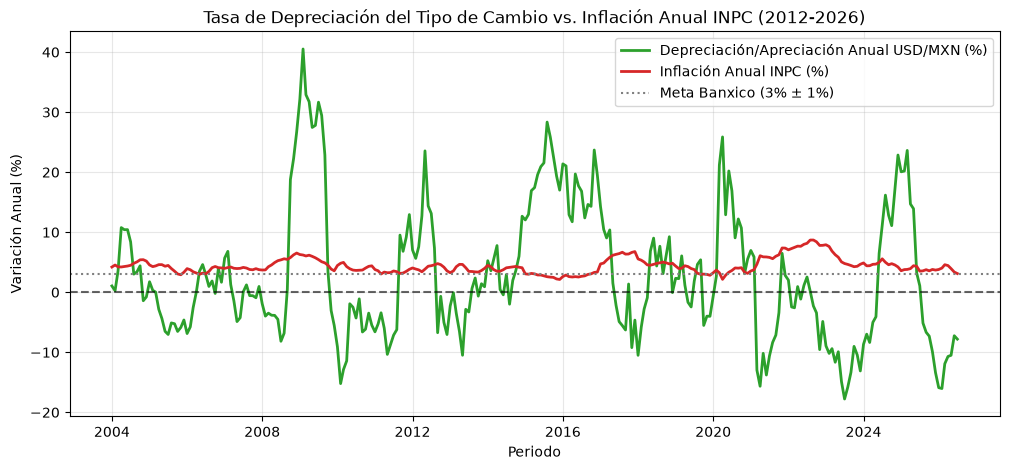

In [4]:
plt.figure(figsize=(12, 5))
plt.plot(df_ret["PERIODO"], df_ret["RET_TC_CIERRE"], label="Depreciación/Apreciación Anual USD/MXN (%)", color="tab:green", linewidth=2)
plt.plot(df_ret["PERIODO"], df_ret["RET_INPC"], label="Inflación Anual INPC (%)", color="tab:red", linewidth=2)
plt.axhline(0, color="black", linestyle="--", alpha=0.6)
plt.axhline(3, color="gray", linestyle=":", label="Meta Banxico (3% ± 1%)")

plt.title("Tasa de Depreciación del Tipo de Cambio vs. Inflación Anual INPC (2012-2026)")
plt.xlabel("Periodo")
plt.ylabel("Variación Anual (%)")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

## Serie de Tiempo: Tipo de Cambio vs. Finanzas Públicas Reales
Muestra la tasa de crecimiento interanual del tipo de cambio frente al crecimiento real de los ingresos y gastos del Gobierno Federal.

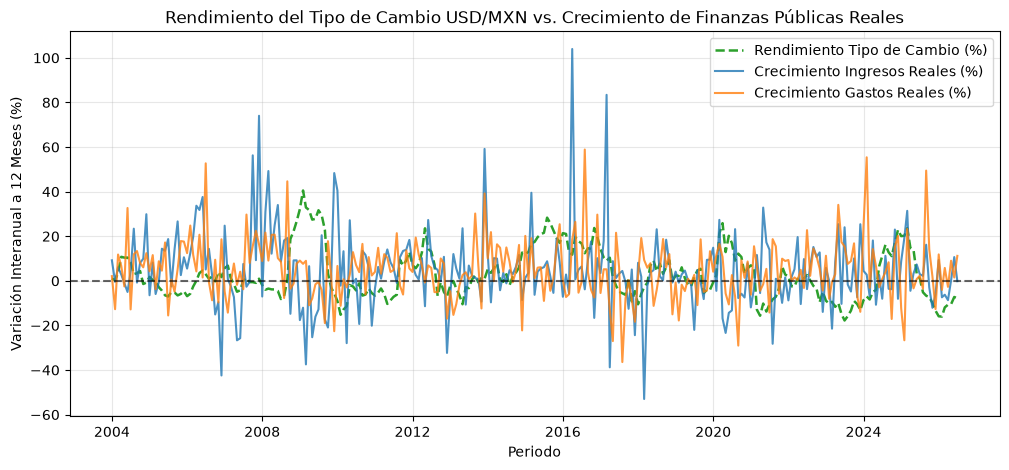

In [5]:
plt.figure(figsize=(12, 5))
plt.plot(df_ret["PERIODO"], df_ret["RET_TC_CIERRE"], label="Rendimiento Tipo de Cambio (%)", color="tab:green", linestyle="--", linewidth=1.8)
plt.plot(df_ret["PERIODO"], df_ret["RET_INGRESOS_REALES"], label="Crecimiento Ingresos Reales (%)", color="tab:blue", alpha=0.8)
plt.plot(df_ret["PERIODO"], df_ret["RET_GASTOS_REALES"], label="Crecimiento Gastos Reales (%)", color="tab:orange", alpha=0.8)
plt.axhline(0, color="black", linestyle="--", alpha=0.6)

plt.title("Rendimiento del Tipo de Cambio USD/MXN vs. Crecimiento de Finanzas Públicas Reales")
plt.xlabel("Periodo")
plt.ylabel("Variación Interanual a 12 Meses (%)")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

## Serie de Tiempo: Tipo de Cambio vs. Crecimiento de Sectores IGAE
Compara la variación cambiaria con el ritmo de crecimiento anual de la economía total, industrial (secundarias) y comercial/servicios (terciarias).

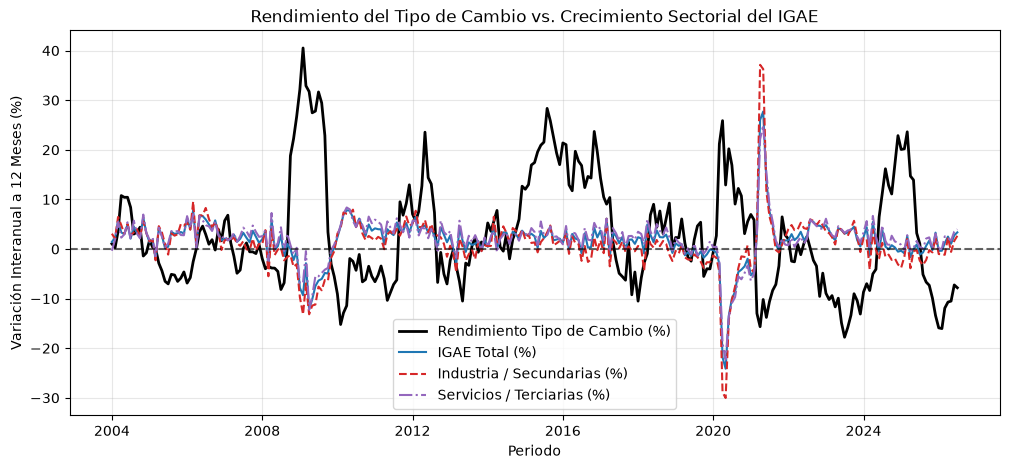

In [6]:
plt.figure(figsize=(12, 5))
plt.plot(df_ret["PERIODO"], df_ret["RET_TC_CIERRE"], label="Rendimiento Tipo de Cambio (%)", color="black", linewidth=2)
plt.plot(df_ret["PERIODO"], df_ret["RET_Total"], label="IGAE Total (%)", color="tab:blue")
plt.plot(df_ret["PERIODO"], df_ret["RET_Actividades secundarias"], label="Industria / Secundarias (%)", color="tab:red", linestyle="--")
plt.plot(df_ret["PERIODO"], df_ret["RET_Actividades terciarias"], label="Servicios / Terciarias (%)", color="tab:purple", linestyle="-.")
plt.axhline(0, color="black", linestyle="--", alpha=0.6)

plt.title("Rendimiento del Tipo de Cambio vs. Crecimiento Sectorial del IGAE")
plt.xlabel("Periodo")
plt.ylabel("Variación Interanual a 12 Meses (%)")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

## Diagramas de Dispersión (Scatter Plots)
Exploración de la dispersión del rendimiento del Tipo de Cambio frente a la Inflación, el IGAE Total, la Industria y los Ingresos Reales.

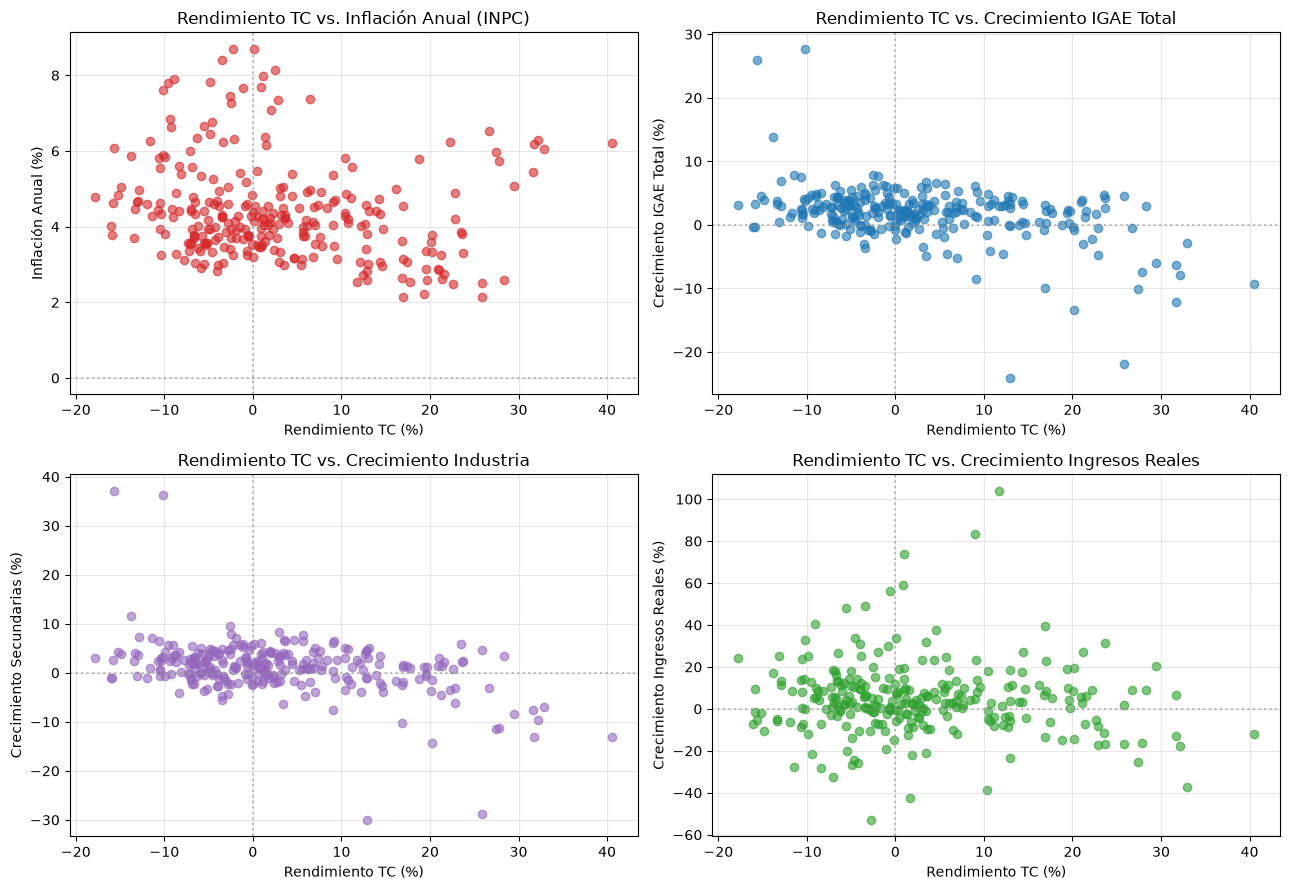

In [7]:
fig, axes = plt.subplots(2, 2, figsize=(13, 9))

# TC vs Inflación (INPC)
axes[0, 0].scatter(df_ret["RET_TC_CIERRE"], df_ret["RET_INPC"], alpha=0.6, color="tab:red")
axes[0, 0].set_title("Rendimiento TC vs. Inflación Anual (INPC)")
axes[0, 0].set_xlabel("Rendimiento TC (%)")
axes[0, 0].set_ylabel("Inflación Anual (%)")
axes[0, 0].axvline(0, color="gray", linestyle=":", alpha=0.5)
axes[0, 0].axhline(0, color="gray", linestyle=":", alpha=0.5)
axes[0, 0].grid(True, alpha=0.3)

# TC vs IGAE Total
axes[0, 1].scatter(df_ret["RET_TC_CIERRE"], df_ret["RET_Total"], alpha=0.6, color="tab:blue")
axes[0, 1].set_title("Rendimiento TC vs. Crecimiento IGAE Total")
axes[0, 1].set_xlabel("Rendimiento TC (%)")
axes[0, 1].set_ylabel("Crecimiento IGAE Total (%)")
axes[0, 1].axvline(0, color="gray", linestyle=":", alpha=0.5)
axes[0, 1].axhline(0, color="gray", linestyle=":", alpha=0.5)
axes[0, 1].grid(True, alpha=0.3)

# TC vs IGAE Secundarias (Industria)
axes[1, 0].scatter(df_ret["RET_TC_CIERRE"], df_ret["RET_Actividades secundarias"], alpha=0.6, color="tab:purple")
axes[1, 0].set_title("Rendimiento TC vs. Crecimiento Industria")
axes[1, 0].set_xlabel("Rendimiento TC (%)")
axes[1, 0].set_ylabel("Crecimiento Secundarias (%)")
axes[1, 0].axvline(0, color="gray", linestyle=":", alpha=0.5)
axes[1, 0].axhline(0, color="gray", linestyle=":", alpha=0.5)
axes[1, 0].grid(True, alpha=0.3)

# TC vs Ingresos Reales
axes[1, 1].scatter(df_ret["RET_TC_CIERRE"], df_ret["RET_INGRESOS_REALES"], alpha=0.6, color="tab:green")
axes[1, 1].set_title("Rendimiento TC vs. Crecimiento Ingresos Reales")
axes[1, 1].set_xlabel("Rendimiento TC (%)")
axes[1, 1].set_ylabel("Crecimiento Ingresos Reales (%)")
axes[1, 1].axvline(0, color="gray", linestyle=":", alpha=0.5)
axes[1, 1].axhline(0, color="gray", linestyle=":", alpha=0.5)
axes[1, 1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

## Matriz de Correlación Lineal de Pearson (Rendimientos)
Medición paramétrica única de la asociación lineal entre las variaciones interanuales.

Correlación de Pearson frente al Rendimiento del Tipo de Cambio:


,RET_TC_CIERRE
RET_TC_CIERRE,1.0000
RET_INPC,-0.1805
RET_INGRESOS_REALES,-0.0721
RET_GASTOS_REALES,-0.0587
RET_Total,-0.4207
RET_Actividades primarias,0.0133
RET_Actividades secundarias,-0.4040
RET_Actividades terciarias,-0.4192


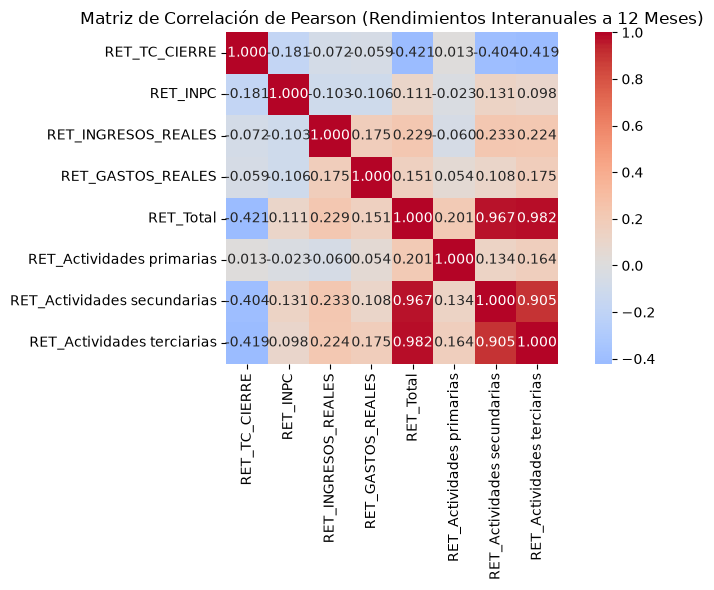

In [8]:
cols_ret = [f"RET_{c}" for c in cols_analisis]
corr_ret = df_ret[cols_ret].corr(method="pearson")

print("Correlación de Pearson frente al Rendimiento del Tipo de Cambio:")
display(corr_ret[["RET_TC_CIERRE"]].round(4))

plt.figure(figsize=(9, 6))
sns.heatmap(corr_ret, annot=True, cmap="coolwarm", center=0, fmt=".3f", square=True)
plt.title("Matriz de Correlación de Pearson (Rendimientos Interanuales a 12 Meses)")
plt.tight_layout()
plt.show()